# Airline Review Analysis - Notebook 3: Text Preprocessing

Computers cannot work with raw sentences directly, so the review text first has to be cleaned and broken into smaller pieces. In this notebook I go through the standard preprocessing steps one by one, first on a single review and then on all reviews.

Syllabus topics used here (Unit 1, word level analysis):
- regular expressions
- tokenization
- stopword removal
- stemming (Porter stemmer) and lemmatization
- n-grams and a simple n-gram language model

Input: `data/reviews_clean.csv`
Output: `data/reviews_preprocessed.csv` (same data plus a `text_clean` column)

## 1. Setup

In [1]:
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

sns.set_style("whitegrid")
df = pd.read_csv("data/reviews_clean.csv", parse_dates=["review_date"])
print(df.shape)

(64331, 23)


## 2. Working on one review first

I pick one review and apply each step to it so I can see what changes.

In [2]:
sample = df.loc[df["airline"] == "Spicejet"].iloc[1]["review_text"]
print(sample)

The flight was postponed 3 times with insufficient explanation. Highly inconvenient to fly with Spicejet with such pathetic time management. Secondly, the air condition in the plane was blasting making it uncomfortable for several passengers. When asked for blankets, the flight attendants informed that the blankets were reserved only for spicemax passengers. There needs to be a provision for such basic services. Thirdly, unnecessary announcement during late night flights. All of these experiences aggregated to making this highly inconvenient journey. I wouldnt recommend Spicejet to my friends and family.


### 2.1 Lowercasing

"Flight" and "flight" should be treated as the same word.

In [3]:
step1 = sample.lower()
print(step1)

the flight was postponed 3 times with insufficient explanation. highly inconvenient to fly with spicejet with such pathetic time management. secondly, the air condition in the plane was blasting making it uncomfortable for several passengers. when asked for blankets, the flight attendants informed that the blankets were reserved only for spicemax passengers. there needs to be a provision for such basic services. thirdly, unnecessary announcement during late night flights. all of these experiences aggregated to making this highly inconvenient journey. i wouldnt recommend spicejet to my friends and family.


### 2.2 Cleaning with regular expressions

Reviews contain punctuation, numbers and curly apostrophes. I use `re.sub` to remove everything that is not a letter or a space. Before that I expand short forms like "didn't" (and "didnt", which many reviewers type without the apostrophe) into "did not", because the word "not" changes the meaning of a sentence and I do not want to lose it.

In [4]:
def expand_contractions(text):
    text = text.replace("’", "'")             # curly apostrophe -> normal apostrophe
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "can not", text)
    text = re.sub(r"n't", " not", text)       # didn't -> did not, wasn't -> was not
    # many reviewers type these without the apostrophe: wouldnt, dont, wasnt ...
    text = re.sub(r"\b(did|does|do|was|were|is|are|would|could|should|have|has|had|can)nt\b", r"\1 not", text)
    text = re.sub(r"\bwont\b", "will not", text)
    return text

step2 = expand_contractions(step1)
step2 = re.sub(r"[^a-z\s]", " ", step2)      # keep only letters and spaces
step2 = re.sub(r"\s+", " ", step2).strip()    # remove extra spaces
print(step2)

the flight was postponed times with insufficient explanation highly inconvenient to fly with spicejet with such pathetic time management secondly the air condition in the plane was blasting making it uncomfortable for several passengers when asked for blankets the flight attendants informed that the blankets were reserved only for spicemax passengers there needs to be a provision for such basic services thirdly unnecessary announcement during late night flights all of these experiences aggregated to making this highly inconvenient journey i would not recommend spicejet to my friends and family


### 2.2.1 Where regular expressions are useful on their own

Regular expressions can also be used to find patterns in the raw text. For example, how many reviews mention a delay in hours, such as "3 hours" or "2 hrs"?

In [5]:
hours_pattern = r"\d+\s*(?:hours?|hrs?)\b"

mentions_hours = df["review_text"].str.contains(hours_pattern, case=False, regex=True)
print("reviews that mention a number of hours:", mentions_hours.sum(),
      "(" + str(round(mentions_hours.mean() * 100, 1)) + "%)")

# the matching pieces from a few reviews
print(df.loc[mentions_hours, "review_text"].head(3).str.findall(hours_pattern, flags=re.I).tolist())

reviews that mention a number of hours: 17201 (26.7%)
[['30 hours'], ['6 hours'], ['1 hr']]


### 2.3 Tokenization

Tokenization splits the text into words (tokens). The simplest way is `split()`. NLTK's `word_tokenize` is smarter about punctuation and short forms, which I compare below.

In [6]:
example = "I didn't get my bags, and the crew couldn't help."
print("split()      :", example.split())
print("word_tokenize:", word_tokenize(example))

split()      : ['I', "didn't", 'get', 'my', 'bags,', 'and', 'the', 'crew', "couldn't", 'help.']
word_tokenize: ['I', 'did', "n't", 'get', 'my', 'bags', ',', 'and', 'the', 'crew', 'could', "n't", 'help', '.']


In [7]:
tokens = step2.split()
print(len(tokens), "tokens")
print(tokens[:20])

89 tokens
['the', 'flight', 'was', 'postponed', 'times', 'with', 'insufficient', 'explanation', 'highly', 'inconvenient', 'to', 'fly', 'with', 'spicejet', 'with', 'such', 'pathetic', 'time', 'management', 'secondly']


After my regex cleaning there is no punctuation left, so `split()` is enough for the whole dataset (and it is much faster than `word_tokenize` on 64,000 reviews).

### 2.4 Stopword removal

Stopwords are very common words (the, is, and, to) that carry little meaning. NLTK has a ready list.

In [8]:
stop_words = set(stopwords.words("english"))
print("number of stopwords:", len(stop_words))
print(sorted(stop_words)[:30])

number of stopwords: 198
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't"]


There is a problem for sentiment analysis. The NLTK list also contains words like "not", "no", "never" and "nor", and these are exactly the words that flip the meaning ("not recommend"). Let me check what happens to a sentence if I use the list as it is.

In [9]:
sentence = "i would not recommend this airline and there was no help"
words = sentence.split()

print("default list  :", [w for w in words if w not in stop_words])

default list  : ['would', 'recommend', 'airline', 'help']


In [10]:
negations = {"no", "not", "nor", "never", "none", "nothing", "neither", "without"}
my_stop_words = stop_words - negations

print("negations kept:", [w for w in words if w not in my_stop_words])

negations kept: ['would', 'not', 'recommend', 'airline', 'no', 'help']


So I remove the negation words from the stopword list and keep them in the text.

In [11]:
tokens_nostop = [w for w in tokens if w not in my_stop_words]
print(len(tokens), "tokens ->", len(tokens_nostop), "tokens after removing stopwords")
print(tokens_nostop)

89 tokens -> 52 tokens after removing stopwords
['flight', 'postponed', 'times', 'insufficient', 'explanation', 'highly', 'inconvenient', 'fly', 'spicejet', 'pathetic', 'time', 'management', 'secondly', 'air', 'condition', 'plane', 'blasting', 'making', 'uncomfortable', 'several', 'passengers', 'asked', 'blankets', 'flight', 'attendants', 'informed', 'blankets', 'reserved', 'spicemax', 'passengers', 'needs', 'provision', 'basic', 'services', 'thirdly', 'unnecessary', 'announcement', 'late', 'night', 'flights', 'experiences', 'aggregated', 'making', 'highly', 'inconvenient', 'journey', 'would', 'not', 'recommend', 'spicejet', 'friends', 'family']


### 2.5 Stemming and lemmatization

Both reduce words to a base form so that "delay", "delayed" and "delays" count as one word.

- **Stemming** chops off word endings with rules (Porter stemmer). It is fast but the result may not be a real word.
- **Lemmatization** uses a dictionary (WordNet) to return the real base word. It needs to know whether the word is a noun or a verb.

In [12]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words = ["delayed", "delays", "delaying", "flights", "flying", "cancelled", "luggage",
         "uncomfortable", "better", "was", "crews", "boarding"]

comparison = pd.DataFrame({
    "word": words,
    "stem": [stemmer.stem(w) for w in words],
    "lemma (noun)": [lemmatizer.lemmatize(w, pos="n") for w in words],
    "lemma (verb)": [lemmatizer.lemmatize(w, pos="v") for w in words],
})
comparison

,word,stem,lemma (noun),lemma (verb)
0,delayed,delay,delayed,delay
1,delays,delay,delay,delay
2,delaying,delay,delaying,delay
3,flights,flight,flight,flight
4,flying,fli,flying,fly
5,cancelled,cancel,cancelled,cancel
6,luggage,luggag,luggage,luggage
7,uncomfortable,uncomfort,uncomfortable,uncomfortable
8,better,better,better,better
9,was,wa,wa,be


The stemmer gives "fli" for "flying" and "uncomfort" for "uncomfortable", which are not real words and would be hard to read in the results. Lemmatization gives proper words (flying -> fly, cancelled -> cancel), but a word like "delayed" or "flying" only changes when it is treated as a verb, so the lemmatizer needs to know the part of speech.

I will use **lemmatization**, applying the verb form first and then the noun form, so the output stays readable.

## 3. Putting all steps into one function

In [13]:
lemma_cache = {}     # remember each word's lemma so it is only calculated once

keep_as_is = {"ground"}   # the verb form of 'ground' is 'grind', which breaks 'ground staff'

def get_lemma(word):
    if word in keep_as_is:
        return word
    if word not in lemma_cache:
        lemma = lemmatizer.lemmatize(word, pos="v")
        lemma = lemmatizer.lemmatize(lemma, pos="n")
        lemma_cache[word] = lemma
    return lemma_cache[word]


def preprocess(text):
    text = text.lower()
    text = expand_contractions(text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    tokens = [w for w in tokens if w not in my_stop_words and len(w) > 2]
    tokens = [get_lemma(w) for w in tokens]
    return " ".join(tokens)

print(preprocess(sample))

flight postpone time insufficient explanation highly inconvenient fly spicejet pathetic time management secondly air condition plane blast make uncomfortable several passenger ask blanket flight attendant inform blanket reserve spicemax passenger need provision basic service thirdly unnecessary announcement late night flight experience aggregate make highly inconvenient journey would not recommend spicejet friend family


Applying the function to all reviews (this takes a minute or two):

In [14]:
df["text_clean"] = df["review_text"].apply(preprocess)

df["n_tokens_clean"] = df["text_clean"].str.split().str.len()
print("average words before:", round(df["n_words"].mean(), 1))
print("average words after :", round(df["n_tokens_clean"].mean(), 1))
df[["review_text", "text_clean"]].head(3)

average words before: 135.2
average words after : 67.6


,review_text,text_clean
0,My afternoon flight was delayed and eventually...,afternoon flight delay eventually fly complete...
1,The flight was postponed 3 times with insuffic...,flight postpone time insufficient explanation ...
2,They will charge you for your hand baggage if ...,charge hand baggage exceed include laptop grou...


About half of the words are removed, so the remaining text is much more focused on meaningful words.

## 4. Most common words

First the most frequent words overall. I count words separately for reviews that recommend the airline and reviews that do not.

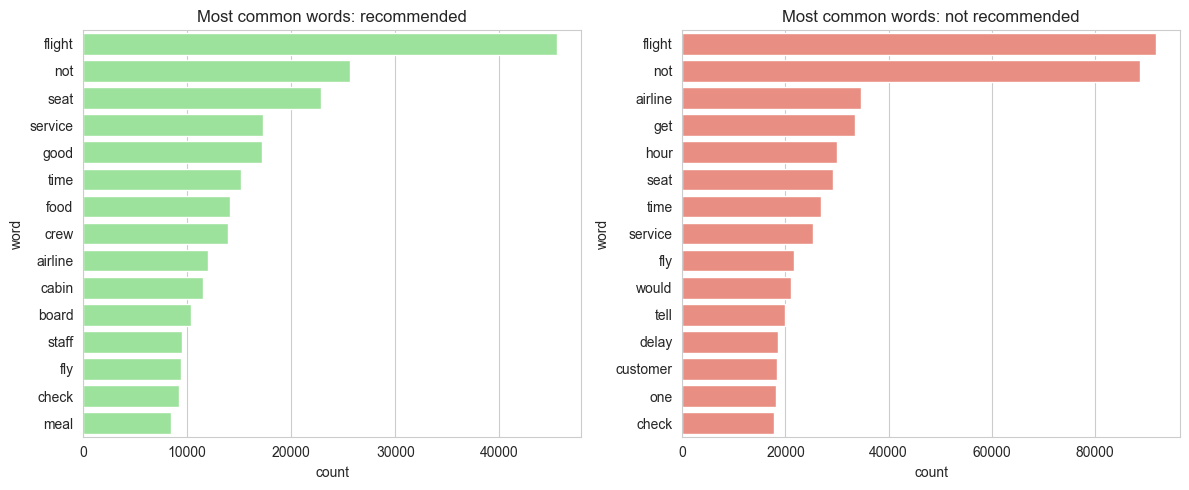

In [15]:
words_yes = Counter(" ".join(df.loc[df["recommended"] == "yes", "text_clean"]).split())
words_no = Counter(" ".join(df.loc[df["recommended"] == "no", "text_clean"]).split())

top_yes = pd.DataFrame(words_yes.most_common(15), columns=["word", "count"])
top_no = pd.DataFrame(words_no.most_common(15), columns=["word", "count"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=top_yes, x="count", y="word", color="lightgreen", ax=axes[0])
axes[0].set_title("Most common words: recommended")
sns.barplot(data=top_no, x="count", y="word", color="salmon", ax=axes[1])
axes[1].set_title("Most common words: not recommended")
plt.tight_layout()
plt.show()

Many words appear in both lists ("flight", "seat", "service", "time", "airline"), because both groups of passengers talk about the same things, so raw counts mostly show the topics of conversation. Some differences are visible: "good", "food" and "crew" for recommended reviews, and "hour", "delay" and "tell" for the others. The word "not" is the second most common word in both lists, which shows why it was important to keep negations.

To see the difference more clearly, I compare how often a word appears in each group. For every word I calculate how many times it appears per 1000 words in each group, and then the ratio between the two.

In [16]:
total_yes = sum(words_yes.values())
total_no = sum(words_no.values())

rows = []
for word in set(words_yes) | set(words_no):
    count_yes = words_yes.get(word, 0)
    count_no = words_no.get(word, 0)
    if count_yes + count_no >= 500:            # ignore rare words
        rate_yes = count_yes / total_yes * 1000
        rate_no = count_no / total_no * 1000
        rows.append([word, rate_yes, rate_no, (rate_no + 0.01) / (rate_yes + 0.01)])

compare = pd.DataFrame(rows, columns=["word", "per_1000_yes", "per_1000_no", "ratio_no_to_yes"])

print("Words most typical of NOT recommended reviews:")
print(compare.sort_values("ratio_no_to_yes", ascending=False).head(15).round(2).to_string(index=False))
print()
print("Words most typical of recommended reviews:")
print(compare.sort_values("ratio_no_to_yes").head(15).round(2).to_string(index=False))

Words most typical of NOT recommended reviews:
          word  per_1000_yes  per_1000_no  ratio_no_to_yes
        refund          0.19         2.45            12.48
 reimbursement          0.01         0.17            11.25
        refuse          0.12         1.19             9.39
         worst          0.20         1.90             9.22
  compensation          0.10         0.97             9.19
     reimburse          0.02         0.28             8.96
responsibility          0.02         0.28             8.66
        submit          0.02         0.23             8.11
          file          0.04         0.36             7.94
     unhelpful          0.03         0.32             7.75
        strand          0.03         0.31             7.44
      tomorrow          0.02         0.18             7.29
        rebook          0.05         0.45             7.26
          deny          0.04         0.35             7.12
       expense          0.03         0.28             7.02

Words mo

Now there is a clear difference. The words typical of unhappy passengers are about refunds, reimbursement, compensation, refusals and being stranded ("refund", "reimbursement", "refuse", "compensation", "strand"), while happy passengers use praise words like "delicious", "excellent", "tasty" and "attentive".

## 5. N-grams

An n-gram is a group of n words that appear next to each other. Bigrams (n = 2) are useful because many ideas need two words, such as "customer service" or "cabin crew".

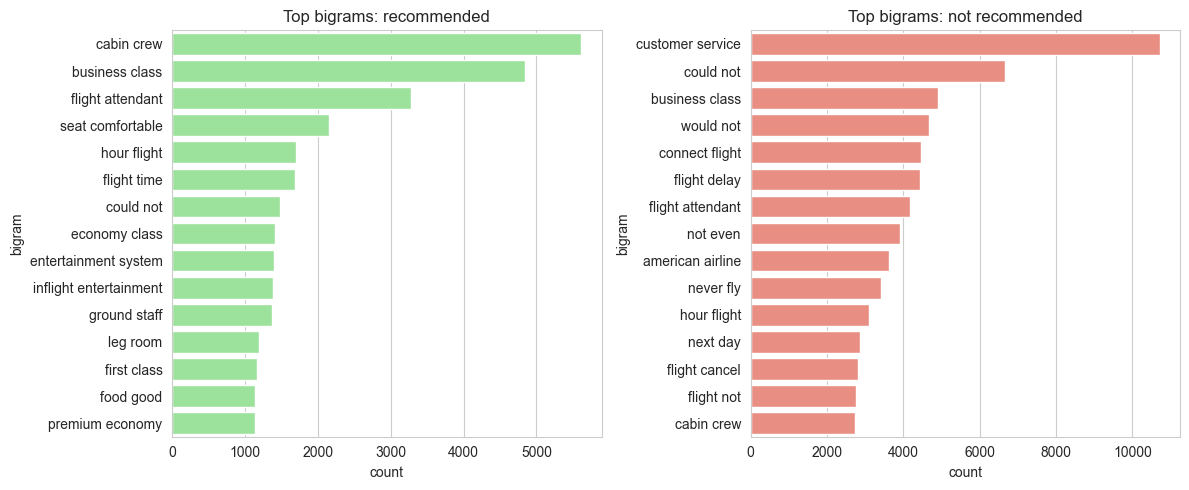

In [17]:
def get_bigrams(text):
    words = text.split()
    return list(zip(words, words[1:]))

bigrams_yes = Counter()
bigrams_no = Counter()
for text in df.loc[df["recommended"] == "yes", "text_clean"]:
    bigrams_yes.update(get_bigrams(text))
for text in df.loc[df["recommended"] == "no", "text_clean"]:
    bigrams_no.update(get_bigrams(text))

top_bi_yes = pd.DataFrame([(" ".join(b), c) for b, c in bigrams_yes.most_common(15)], columns=["bigram", "count"])
top_bi_no = pd.DataFrame([(" ".join(b), c) for b, c in bigrams_no.most_common(15)], columns=["bigram", "count"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=top_bi_yes, x="count", y="bigram", color="lightgreen", ax=axes[0])
axes[0].set_title("Top bigrams: recommended")
sns.barplot(data=top_bi_no, x="count", y="bigram", color="salmon", ax=axes[1])
axes[1].set_title("Top bigrams: not recommended")
plt.tight_layout()
plt.show()

Bigrams give more context than single words. The "not recommended" reviews contain phrases about specific problems such as "customer service", "flight delay", "flight cancel", "never fly" and "next day", while the recommended reviews have "cabin crew", "seat comfortable", "leg room" and "food good". I will use bigrams again later to describe the main complaints about each topic.

### A small bigram language model

An n-gram language model predicts the next word using the previous word(s). With bigrams, the probability of the next word is:

P(next word | previous word) = count(previous word, next word) / count(previous word)

I build this on the lowercased text (without removing stopwords, so the sentences stay natural), using a sample of 20,000 reviews to keep it quick.

In [18]:
sample_texts = df["review_text"].sample(20000, random_state=1)

unigram_counts = Counter()
bigram_counts = Counter()
for text in sample_texts:
    words = re.sub(r"[^a-z\s]", " ", expand_contractions(text.lower())).split()
    unigram_counts.update(words)
    bigram_counts.update(zip(words, words[1:]))

def next_word_probabilities(word, top=5):
    options = [(pair[1], count / unigram_counts[word])
               for pair, count in bigram_counts.items() if pair[0] == word]
    return sorted(options, key=lambda x: x[1], reverse=True)[:top]

for w in ["customer", "cabin", "would"]:
    print("after '" + w + "':", [(nxt, round(p, 2)) for nxt, p in next_word_probabilities(w)])

after 'customer': [('service', 0.71), ('care', 0.04), ('support', 0.03), ('services', 0.02), ('relations', 0.01)]
after 'cabin': [('crew', 0.44), ('staff', 0.07), ('was', 0.06), ('service', 0.03), ('and', 0.02)]
after 'would': [('not', 0.19), ('be', 0.17), ('have', 0.14), ('recommend', 0.02), ('like', 0.02)]


For example, after "customer" the most likely next word is "service", and after "cabin" it is "crew". The model has learned these patterns just by counting.

## 6. Saving the preprocessed data

In [19]:
df.to_csv("data/reviews_preprocessed.csv", index=False)
print("saved", len(df), "reviews with the new text_clean column")

saved 64331 reviews with the new text_clean column


## Summary

- Steps used: lowercasing, expanding contractions, regex cleaning, tokenization, stopword removal, lemmatization.
- I kept negation words (not, no, never) out of the stopword list, because they change the meaning of a sentence.
- Lemmatization was preferred over stemming because the results are real words.
- Comparing word rates in the two groups shows which words separate happy from unhappy passengers, better than raw counts.
- Bigrams add context, and a simple bigram model can predict the next word.

Note for later: the sentiment models in the next notebook work on the original review text, and `text_clean` is used mainly for word counts and phrases.

Next notebook: sentiment classification (VADER, Naive Bayes and Logistic Regression).